In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
import seaborn as sns
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier
from sklearn.ensemble import VotingClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.model_selection import learning_curve

Carga de datos

In [2]:
df = pd.read_csv("../data/Customer-Churn-Records.csv")

Análisis exploratorio

In [3]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425


In [4]:
df.shape

(10000, 18)

In [5]:
df.columns.tolist()

['RowNumber',
 'CustomerId',
 'Surname',
 'CreditScore',
 'Geography',
 'Gender',
 'Age',
 'Tenure',
 'Balance',
 'NumOfProducts',
 'HasCrCard',
 'IsActiveMember',
 'EstimatedSalary',
 'Exited',
 'Complain',
 'Satisfaction Score',
 'Card Type',
 'Point Earned']

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   RowNumber           10000 non-null  int64  
 1   CustomerId          10000 non-null  int64  
 2   Surname             10000 non-null  object 
 3   CreditScore         10000 non-null  int64  
 4   Geography           10000 non-null  object 
 5   Gender              10000 non-null  object 
 6   Age                 10000 non-null  int64  
 7   Tenure              10000 non-null  int64  
 8   Balance             10000 non-null  float64
 9   NumOfProducts       10000 non-null  int64  
 10  HasCrCard           10000 non-null  int64  
 11  IsActiveMember      10000 non-null  int64  
 12  EstimatedSalary     10000 non-null  float64
 13  Exited              10000 non-null  int64  
 14  Complain            10000 non-null  int64  
 15  Satisfaction Score  10000 non-null  int64  
 16  Card 

In [7]:
df.isnull().sum()

RowNumber             0
CustomerId            0
Surname               0
CreditScore           0
Geography             0
Gender                0
Age                   0
Tenure                0
Balance               0
NumOfProducts         0
HasCrCard             0
IsActiveMember        0
EstimatedSalary       0
Exited                0
Complain              0
Satisfaction Score    0
Card Type             0
Point Earned          0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

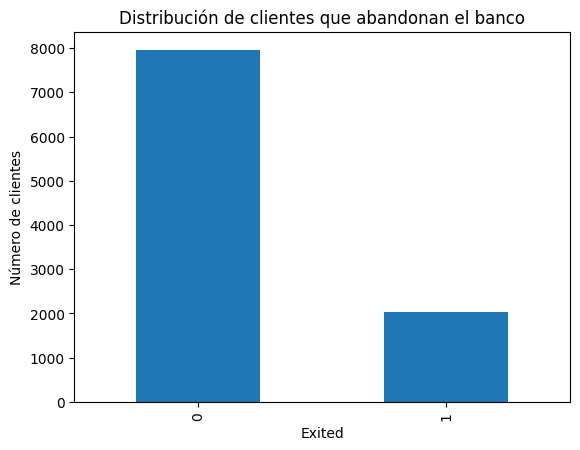

In [9]:
df["Exited"].value_counts().plot(kind="bar")

plt.title("Distribución de clientes que abandonan el banco")
plt.xlabel("Exited")
plt.ylabel("Número de clientes")

plt.show()

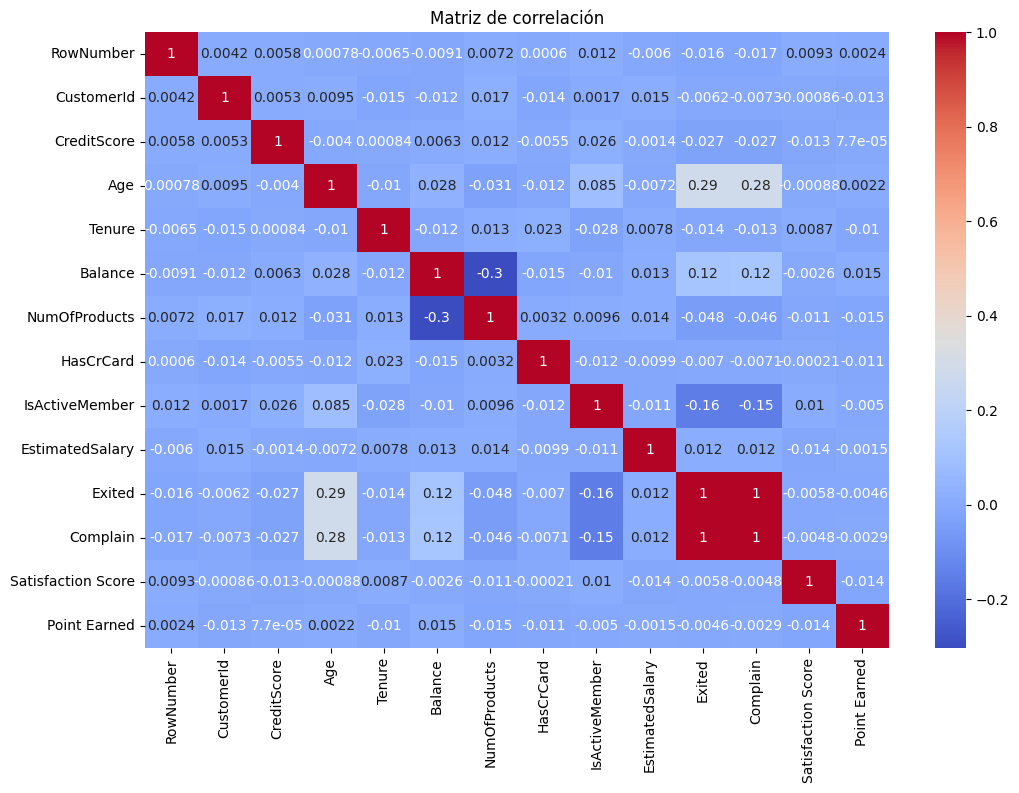

In [10]:

plt.figure(figsize=(12,8))

sns.heatmap(df.corr(numeric_only=True),
            annot=True,
            cmap="coolwarm")

plt.title("Matriz de correlación")

plt.show()

Elimino las variables que considero que no aportan valor.
"Complain" y "Exited" aportan practicamente la misma info, por lo que decido eliminarla para que el modelo no prediga de forma incorrecta.

In [11]:
df = df.drop(["RowNumber", "CustomerId", "Surname", "Complain"], axis=1)

Separo variable objetivo

In [12]:
x = df.drop("Exited", axis=1)
y = df["Exited"]

Separo train y test

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    x,y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

PIPELINE A (basic)

In [14]:
#val numericas
num_features = x.select_dtypes(include=["int64", "float64"]).columns

#val categoricas
cat_features = x.select_dtypes(include=["object"]).columns

print("Num:", list(num_features))
print("Cat:", list(cat_features))

Num: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Satisfaction Score', 'Point Earned']
Cat: ['Geography', 'Gender', 'Card Type']


Aplico transformadores sencillos, numericos ----> media   categoricos ----> valor frecuente

In [15]:
num_transformer_A = Pipeline(steps=[("imputer", SimpleImputer(strategy="mean"))])

cat_transformer_A = Pipeline(steps=[("imputer", SimpleImputer(strategy="most_frequent")),
                                    ("encoder", OneHotEncoder(handle_unknown="ignore"))])

Unifico todo

In [16]:
preprocessor_A = ColumnTransformer([
    ("num", num_transformer_A, num_features),
    ("cat", cat_transformer_A, cat_features)
])

Modelado: Regresion Logistica

In [17]:
modeloLR_pipeline_A = Pipeline([
    ("preprocessor", preprocessor_A),
    ("model", LogisticRegression(random_state=42, max_iter=5000, solver="liblinear"))
])

In [18]:
modeloLR_pipeline_A.fit(X_train, y_train)
prediction_lr = modeloLR_pipeline_A.predict(X_test)

Visualizacion de resultados

In [19]:
print(classification_report(y_test, prediction_lr))

              precision    recall  f1-score   support

           0       0.80      0.99      0.88      1592
           1       0.41      0.03      0.06       408

    accuracy                           0.79      2000
   macro avg       0.61      0.51      0.47      2000
weighted avg       0.72      0.79      0.72      2000



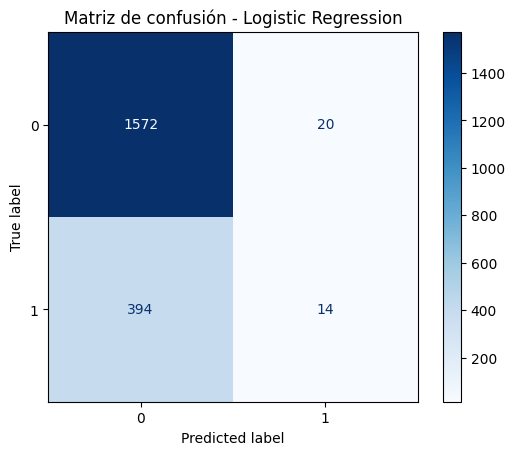

In [20]:
cm = confusion_matrix(y_test, prediction_lr)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap="Blues")
plt.title("Matriz de confusión - Logistic Regression")
plt.show()

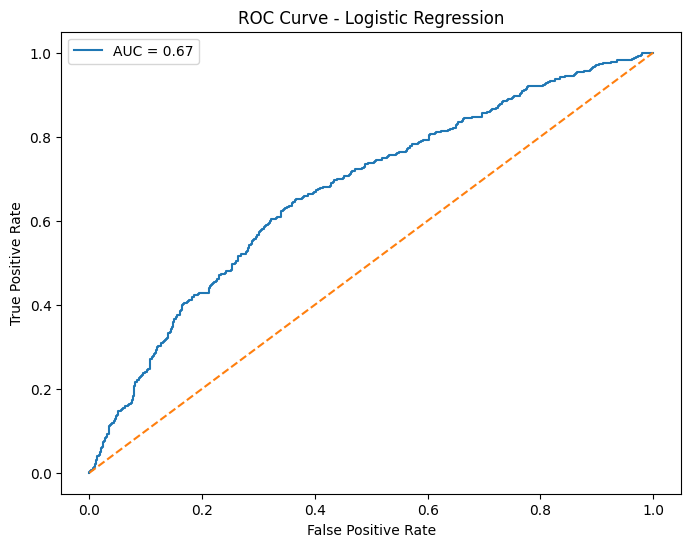

In [21]:
y_probs = modeloLR_pipeline_A.predict_proba(X_test)[:,1]

fpr, tpr, thresholds = roc_curve(y_test, y_probs)
auc_score = roc_auc_score(y_test, y_probs)
plt.figure(figsize=(8,6))

plt.plot(fpr, tpr, label=f"AUC = {auc_score:.2f}")

plt.plot([0,1], [0,1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve - Logistic Regression")

plt.legend()

plt.show()

Modelado: Random Forest

In [22]:
modeloRF_pipeline_A = Pipeline([
    ("processor", preprocessor_A),
    ("model", RandomForestClassifier(
        random_state=42
    ))
])

In [23]:
modeloRF_pipeline_A.fit(X_train, y_train)
prediction_rf = modeloRF_pipeline_A.predict(X_test)

Visualizacion de resultados

In [24]:
print(classification_report(y_test, prediction_rf))

              precision    recall  f1-score   support

           0       0.88      0.97      0.92      1592
           1       0.81      0.47      0.60       408

    accuracy                           0.87      2000
   macro avg       0.84      0.72      0.76      2000
weighted avg       0.86      0.87      0.86      2000



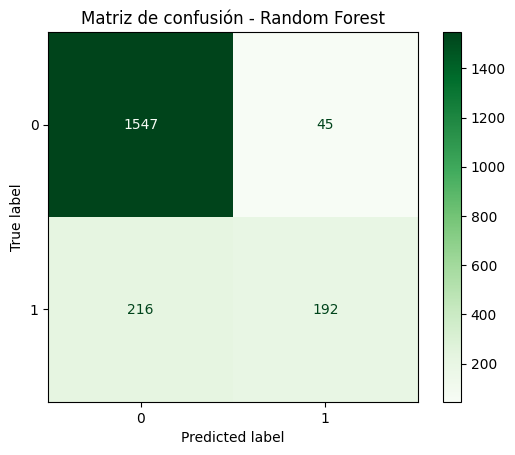

In [25]:
cm_rf = confusion_matrix(y_test, prediction_rf)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_rf)

disp.plot(cmap="Greens")

plt.title("Matriz de confusión - Random Forest")

plt.show()

In [26]:
y_probs_rf = modeloRF_pipeline_A.predict_proba(X_test)[:,1]

In [27]:
fpr_rf, tpr_rf, thresholds_rf = roc_curve(y_test, y_probs_rf)
auc_rf = roc_auc_score(y_test, y_probs_rf)

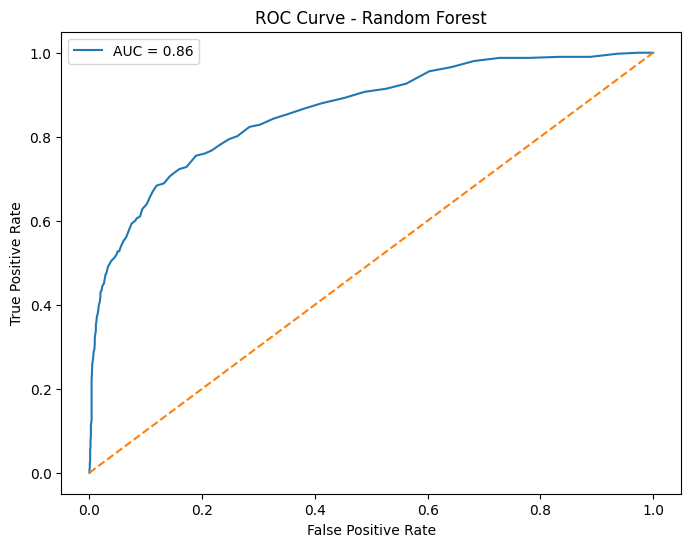

In [28]:
plt.figure(figsize=(8,6))

plt.plot(fpr_rf, tpr_rf, label=f"AUC = {auc_rf:.2f}")

plt.plot([0,1], [0,1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve - Random Forest")

plt.legend()

plt.show()

Obtengo las top 10 val mas importantes

In [29]:
feature_names = modeloRF_pipeline_A.named_steps["processor"].get_feature_names_out()
importances = modeloRF_pipeline_A.named_steps["model"].feature_importances_

In [30]:
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importances
})

importance_df = importance_df.sort_values(by="Importance", ascending=False)

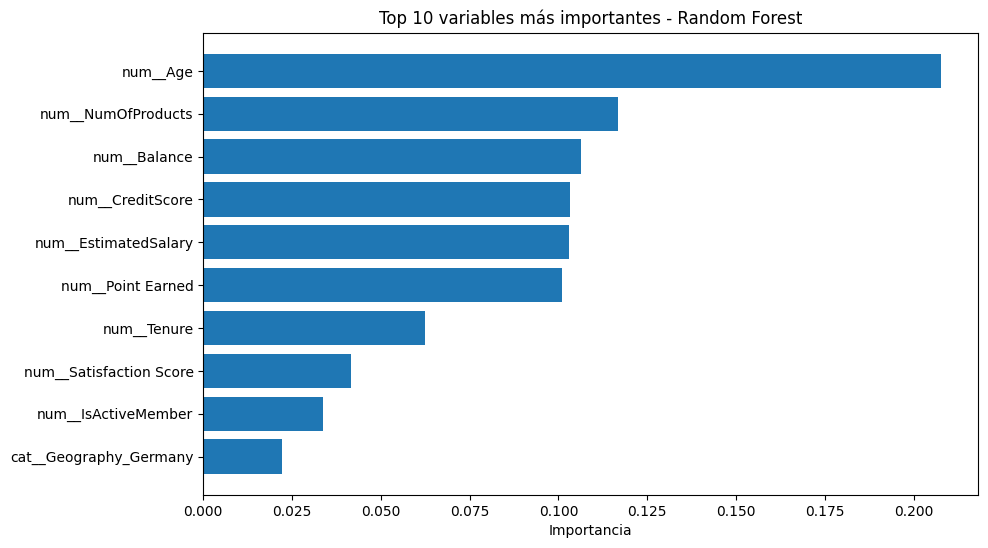

In [31]:
plt.figure(figsize=(10,6))

plt.barh(
    importance_df["Feature"][:10],
    importance_df["Importance"][:10]
)

plt.gca().invert_yaxis()

plt.title("Top 10 variables más importantes - Random Forest")

plt.xlabel("Importancia")

plt.show()

Pipeline B (mejorado)

In [32]:
df_pipeline_B = df.copy()

Creacion de nuevas variables

In [33]:
df_pipeline_B["Age_Balance"] = (df_pipeline_B["Age"] * df_pipeline_B["Balance"])
df_pipeline_B["Credit_Products"] = (df_pipeline_B["CreditScore"] * df_pipeline_B["NumOfProducts"])
df_pipeline_B["Tenure_Salary"] = (df_pipeline_B["Tenure"] * df_pipeline_B["EstimatedSalary"])

In [34]:
#Trato los valores extremos
df_pipeline_B["Balance_log"] = np.log1p(df_pipeline_B["Balance"])
df_pipeline_B["EstimatedSalary_log"] = np.log1p(df_pipeline_B["EstimatedSalary"])

In [35]:
df_pipeline_B.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Satisfaction Score,Card Type,Point Earned,Age_Balance,Credit_Products,Tenure_Salary,Balance_log,EstimatedSalary_log
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1,2,DIAMOND,464,0.00,619,202697.76,0.000000,11.526334
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,3,DIAMOND,456,3436122.26,608,112542.58,11.336294,11.631096
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,3,DIAMOND,377,6705753.60,1506,911452.56,11.980813,11.643362
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0,5,GOLD,350,0.00,1398,93826.63,0.000000,11.449215
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,5,GOLD,425,5396965.26,850,158168.20,11.740155,11.278280


In [36]:
X_B = df_pipeline_B.drop("Exited", axis=1)
y_B = df_pipeline_B["Exited"]

In [37]:
X_train_B, X_test_B, y_train_B, y_test_B = train_test_split(
    X_B,
    y_B,
    test_size=0.2,
    random_state=42,
    stratify=y_B
)

In [38]:
# Variables numéricas
num_features_B = X_train_B.select_dtypes(include=["int64", "float64"]).columns

# Variables categóricas
cat_features_B = X_train_B.select_dtypes(include=["object"]).columns

print("Num:", list(num_features_B))
print("Cat:", list(cat_features_B))

Num: ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Satisfaction Score', 'Point Earned', 'Age_Balance', 'Credit_Products', 'Tenure_Salary', 'Balance_log', 'EstimatedSalary_log']
Cat: ['Geography', 'Gender', 'Card Type']


Transformador numerico y categorico

In [39]:
num_transformer_B = Pipeline([("imputer", SimpleImputer(strategy="mean")),
                              ("scaler", StandardScaler())
])
cat_transformer_B = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

Unifico

In [40]:
preprocessor_B = ColumnTransformer([
    ("num", num_transformer_B, num_features_B),
    ("cat", cat_transformer_B, cat_features_B)
])

Modelado: Regresion Logistica + Pipeline B

In [41]:
modeloLR_pipeline_B = Pipeline([
    ("preprocessor", preprocessor_B),
    ("model", LogisticRegression(
        random_state=42,
        max_iter=5000,
        solver="liblinear",
        class_weight="balanced"
    ))
])

In [42]:
modeloLR_pipeline_B.fit(X_train_B, y_train_B)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers co

In [43]:
prediction_LR_B = modeloLR_pipeline_B.predict(X_test_B)

Visualización de resultados

In [44]:
print(classification_report(y_test_B, prediction_LR_B))

              precision    recall  f1-score   support

           0       0.91      0.71      0.80      1592
           1       0.39      0.72      0.51       408

    accuracy                           0.71      2000
   macro avg       0.65      0.72      0.65      2000
weighted avg       0.80      0.71      0.74      2000



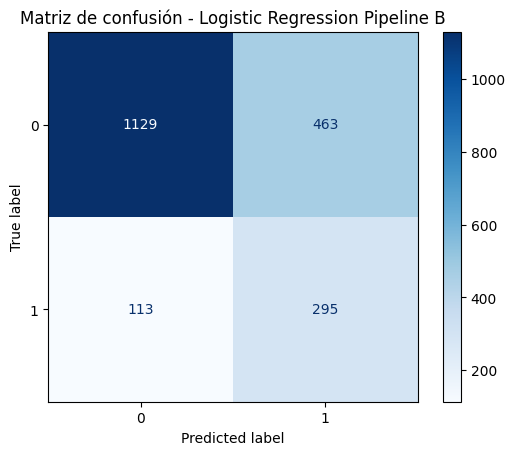

In [45]:
cm_LR_B = confusion_matrix(y_test_B, prediction_LR_B)

disp = ConfusionMatrixDisplay(confusion_matrix=cm_LR_B)

disp.plot(cmap="Blues")

plt.title("Matriz de confusión - Logistic Regression Pipeline B")

plt.show()

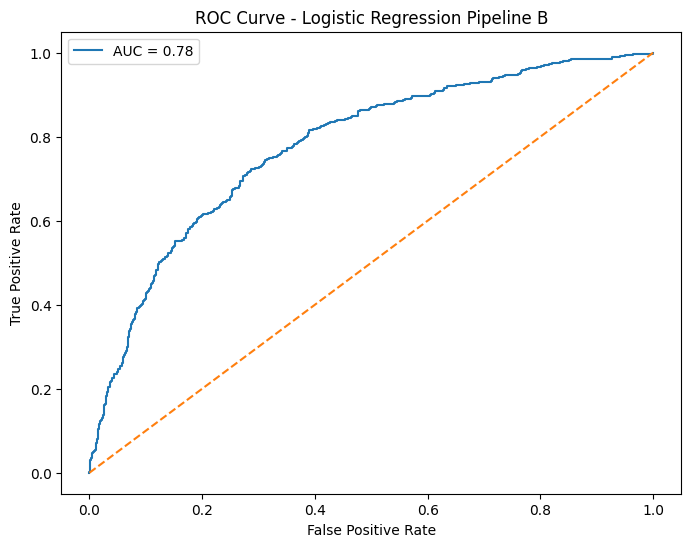

In [46]:
y_probs_LR_B = modeloLR_pipeline_B.predict_proba(X_test_B)[:, 1]

fpr_LR_B, tpr_LR_B, thresholds_LR_B = roc_curve(y_test_B, y_probs_LR_B)

auc_LR_B = roc_auc_score(y_test_B, y_probs_LR_B)

plt.figure(figsize=(8,6))

plt.plot(fpr_LR_B, tpr_LR_B, label=f"AUC = {auc_LR_B:.2f}")

plt.plot([0,1], [0,1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve - Logistic Regression Pipeline B")

plt.legend()

plt.show()

Moedelado: Random Forest + Pipeline B

In [47]:
modeloRF_pipeline_B = Pipeline([
    ("preprocessor", preprocessor_B),
    ("model", RandomForestClassifier(
        random_state=42,
        class_weight="balanced"
    ))
])

In [48]:
modeloRF_pipeline_B.fit(X_train_B, y_train_B)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers co

In [49]:
prediction_RF_B = modeloRF_pipeline_B.predict(X_test_B)

Visualización de los resultados

In [50]:
print(classification_report(y_test_B, prediction_RF_B))

              precision    recall  f1-score   support

           0       0.87      0.97      0.92      1592
           1       0.79      0.44      0.56       408

    accuracy                           0.86      2000
   macro avg       0.83      0.70      0.74      2000
weighted avg       0.86      0.86      0.85      2000



In [51]:
y_probs_RF_B = modeloRF_pipeline_B.predict_proba(X_test_B)[:,1]

In [52]:
fpr_RF_B, tpr_RF_B, thresholds_RF_B = roc_curve(
    y_test_B,
    y_probs_RF_B
)

auc_RF_B = roc_auc_score(y_test_B, y_probs_RF_B)

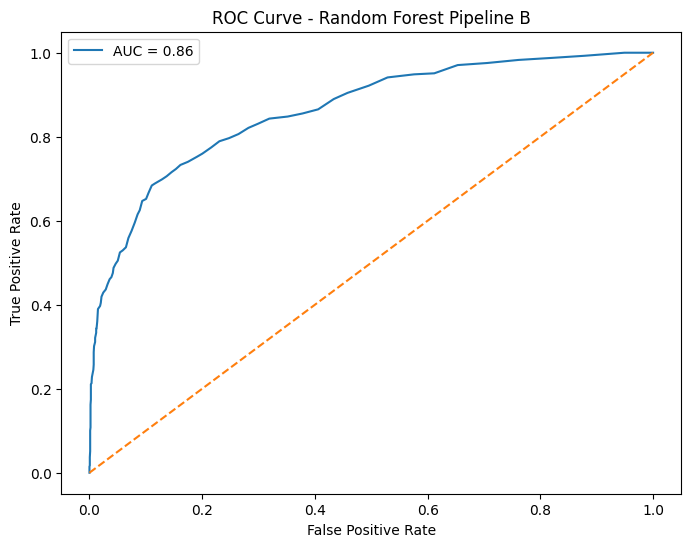

In [53]:
plt.figure(figsize=(8,6))

plt.plot(
    fpr_RF_B,
    tpr_RF_B,
    label=f"AUC = {auc_RF_B:.2f}"
)

plt.plot([0,1], [0,1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve - Random Forest Pipeline B")

plt.legend()

plt.show()

Val importantes

In [54]:
feature_names_B = modeloRF_pipeline_B.named_steps[
    "preprocessor"
].get_feature_names_out()

importances_B = modeloRF_pipeline_B.named_steps[
    "model"
].feature_importances_

In [55]:
importance_df_B = pd.DataFrame({
    "Feature": feature_names_B,
    "Importance": importances_B
})

importance_df_B = importance_df_B.sort_values(
    by="Importance",
    ascending=False
)

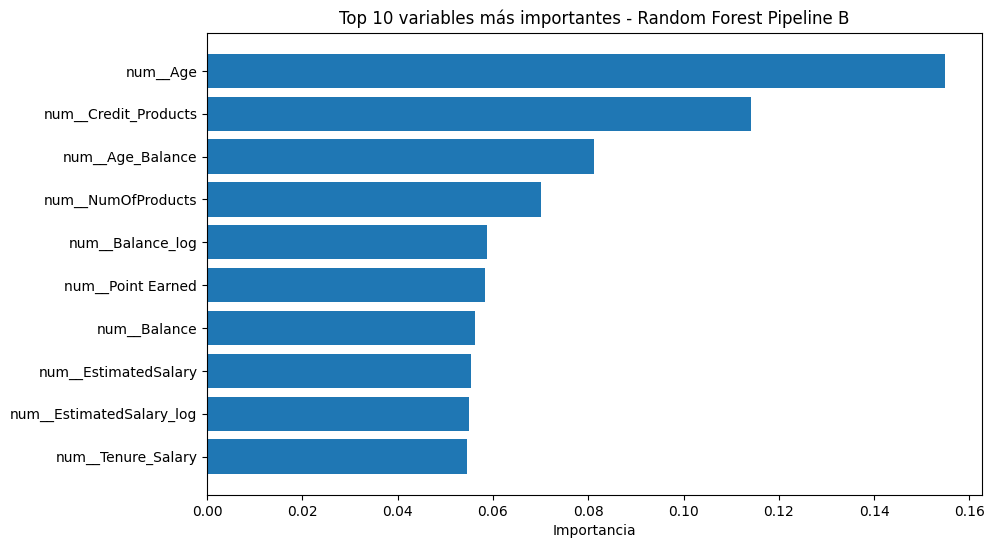

In [56]:
plt.figure(figsize=(10,6))

plt.barh(
    importance_df_B["Feature"][:10],
    importance_df_B["Importance"][:10]
)

plt.gca().invert_yaxis()

plt.title(
    "Top 10 variables más importantes - Random Forest Pipeline B"
)

plt.xlabel("Importancia")

plt.show()

Modelado: Xgboost + Pipeline B

In [57]:
modeloXGB_pipeline_B = Pipeline([
    ("preprocessor", preprocessor_B),
    ("model", XGBClassifier(
        random_state=42,
        eval_metric="logloss"
    ))
])

In [58]:
modeloXGB_pipeline_B.fit(X_train_B, y_train_B)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers co

In [59]:
prediction_XGB_B = modeloXGB_pipeline_B.predict(X_test_B)

Visualizacón de los resultados

In [60]:
print(classification_report(y_test_B, prediction_XGB_B))

              precision    recall  f1-score   support

           0       0.88      0.94      0.91      1592
           1       0.68      0.51      0.58       408

    accuracy                           0.85      2000
   macro avg       0.78      0.73      0.75      2000
weighted avg       0.84      0.85      0.84      2000



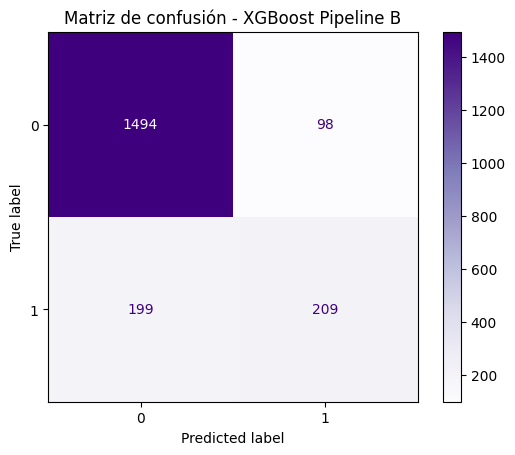

In [61]:
cm_XGB_B = confusion_matrix(y_test_B, prediction_XGB_B)
disp = ConfusionMatrixDisplay(confusion_matrix=cm_XGB_B)
disp.plot(cmap="Purples")
plt.title("Matriz de confusión - XGBoost Pipeline B")
plt.show()

In [62]:
y_probs_XGB_B = modeloXGB_pipeline_B.predict_proba(X_test_B)[:,1]

In [63]:
feature_names_XGB = modeloXGB_pipeline_B.named_steps[
    "preprocessor"
].get_feature_names_out()

importances_XGB = modeloXGB_pipeline_B.named_steps[
    "model"
].feature_importances_

In [64]:
fpr_XGB_B, tpr_XGB_B, thresholds_XGB_B = roc_curve(
    y_test_B,
    y_probs_XGB_B
)
auc_XGB_B = roc_auc_score(
    y_test_B,
    y_probs_XGB_B
)

In [65]:
importance_df_XGB = pd.DataFrame({
    "Feature": feature_names_XGB,
    "Importance": importances_XGB
})

importance_df_XGB = importance_df_XGB.sort_values(
    by="Importance",
    ascending=False
)

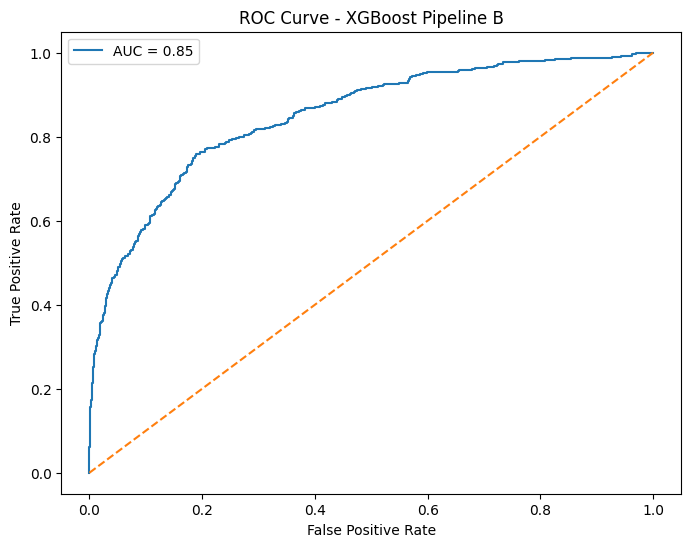

In [66]:
plt.figure(figsize=(8,6))
plt.plot(
    fpr_XGB_B,
    tpr_XGB_B,
    label=f"AUC = {auc_XGB_B:.2f}"
)
plt.plot([0,1], [0,1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - XGBoost Pipeline B")
plt.legend()
plt.show()

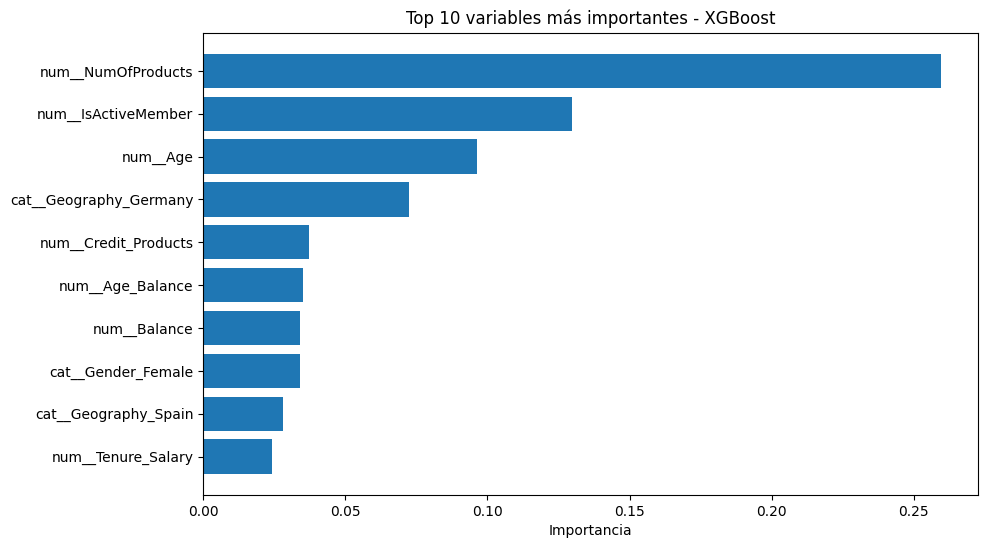

In [67]:
plt.figure(figsize=(10,6))
plt.barh(
    importance_df_XGB["Feature"][:10],
    importance_df_XGB["Importance"][:10]
)
plt.gca().invert_yaxis()
plt.title(
    "Top 10 variables más importantes - XGBoost"
)
plt.xlabel("Importancia")
plt.show()

Modelo ensamblado: VotingClassifer

In [68]:
voting_model = VotingClassifier(
    estimators=[
        ("lr", LogisticRegression(
            random_state=42,
            max_iter=5000,
            solver="liblinear",
            class_weight="balanced"
        )),
        ("rf", RandomForestClassifier(
            random_state=42,
            class_weight="balanced"
        )),
        ("xgb", XGBClassifier(
            random_state=42,
            eval_metric="logloss"
        ))
    ],
    voting="soft"
)

In [69]:
modeloVoting_pipeline_B = Pipeline([
    ("preprocessor", preprocessor_B),
    ("model", voting_model)
])

In [70]:
modeloVoting_pipeline_B.fit(X_train_B, y_train_B)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers co

In [71]:
prediction_Voting_B = modeloVoting_pipeline_B.predict(X_test_B)

In [72]:
print(classification_report(
    y_test_B,
    prediction_Voting_B
))

              precision    recall  f1-score   support

           0       0.89      0.94      0.91      1592
           1       0.70      0.54      0.61       408

    accuracy                           0.86      2000
   macro avg       0.79      0.74      0.76      2000
weighted avg       0.85      0.86      0.85      2000



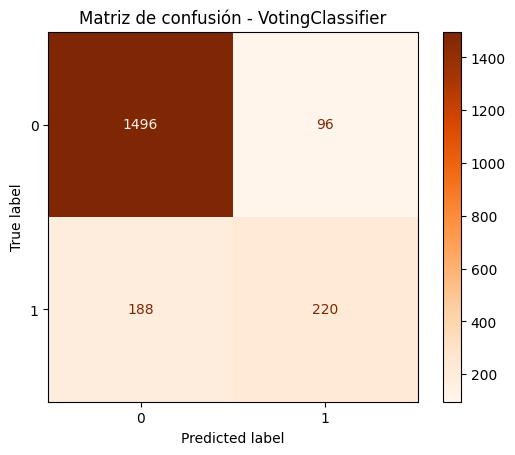

In [73]:
cm_Voting_B = confusion_matrix(
    y_test_B,
    prediction_Voting_B
)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_Voting_B
)
disp.plot(cmap="Oranges")
plt.title(
    "Matriz de confusión - VotingClassifier"
)
plt.show()

In [74]:
y_probs_Voting_B = modeloVoting_pipeline_B.predict_proba(
    X_test_B
)[:,1]

In [75]:
fpr_Voting_B, tpr_Voting_B, thresholds_Voting_B = roc_curve(
    y_test_B,
    y_probs_Voting_B
)
auc_Voting_B = roc_auc_score(
    y_test_B,
    y_probs_Voting_B
)

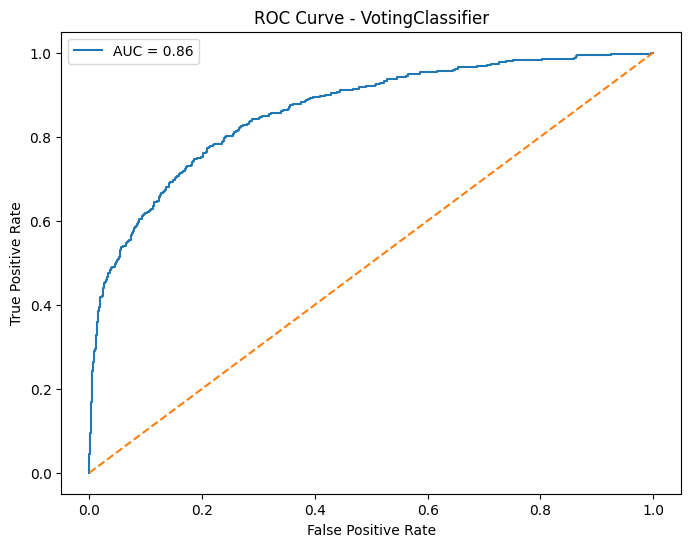

In [76]:
plt.figure(figsize=(8,6))
plt.plot(
    fpr_Voting_B,
    tpr_Voting_B,
    label=f"AUC = {auc_Voting_B:.2f}"
)
plt.plot([0,1], [0,1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - VotingClassifier")
plt.legend()
plt.show()

Tuneado de hiperparámetros para XGBoost

In [77]:
xgb_model_tuning = XGBClassifier(
    random_state=42,
    eval_metric="logloss"
)

In [78]:
param_dist = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [3, 5, 7],
    "model__learning_rate": [0.01, 0.05, 0.1],
    "model__subsample": [0.8, 1.0]
}

In [79]:
pipeline_tuning = Pipeline([
    ("preprocessor", preprocessor_B),
    ("model", xgb_model_tuning)
])

In [80]:
random_search = RandomizedSearchCV(
    estimator=pipeline_tuning,
    param_distributions=param_dist,
    n_iter=10,
    cv=3,
    scoring="f1",
    verbose=2,
    random_state=42,
    n_jobs=-1
)

In [81]:
random_search.fit(X_train_B, y_train_B)

Fitting 3 folds for each of 10 candidates, totalling 30 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","Pipeline(step...=None, ...))])"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__learning_rate': [0.01, 0.05, ...], 'model__max_depth': [3, 5, ...], 'model__n_estimators': [100, 200, ...], 'model__subsample': [0.8, 1.0]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",10
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion ` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'f1'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary `for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given the ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``RandomizedSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`this example`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- An iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide ` for the variouscross-validation strategies that can

In [82]:
print(random_search.best_params_)

{'model__subsample': 1.0, 'model__n_estimators': 100, 'model__max_depth': 7, 'model__learning_rate': 0.1}


In [83]:
print(random_search.best_score_)

0.5808521209586793


In [84]:
best_xgb_model = random_search.best_estimator_

In [85]:
prediction_best_xgb = best_xgb_model.predict(X_test_B)

In [86]:
print(classification_report(
    y_test_B,
    prediction_best_xgb
))

              precision    recall  f1-score   support

           0       0.88      0.95      0.92      1592
           1       0.74      0.51      0.60       408

    accuracy                           0.86      2000
   macro avg       0.81      0.73      0.76      2000
weighted avg       0.85      0.86      0.85      2000



Curva de aprendizaje XGBoost tuneado

In [87]:
train_sizes, train_scores, val_scores = learning_curve(
    best_xgb_model,
    X_B,
    y_B,
    cv=3,
    scoring="f1",
    train_sizes=np.linspace(0.1, 1.0, 5),
    n_jobs=-1
)

In [88]:
train_mean = np.mean(train_scores, axis=1)
val_mean = np.mean(val_scores, axis=1)

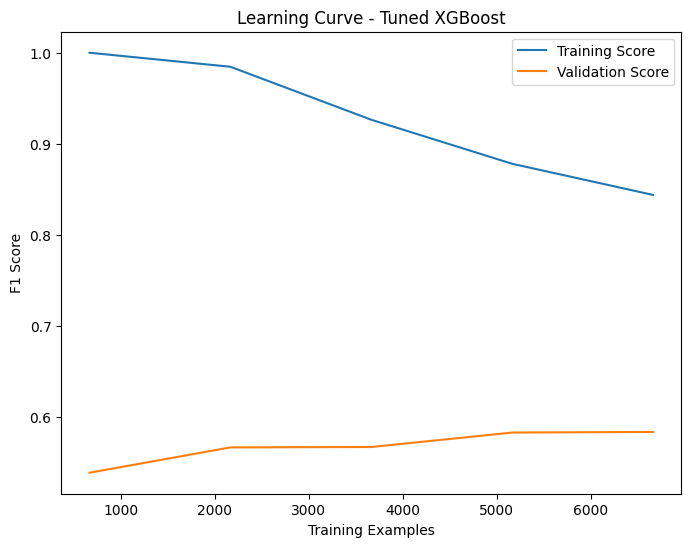

In [89]:
plt.figure(figsize=(8,6))
plt.plot(
    train_sizes,
    train_mean,
    label="Training Score"
)
plt.plot(
    train_sizes,
    val_mean,
    label="Validation Score"
)
plt.title("Learning Curve - Tuned XGBoost")
plt.xlabel("Training Examples")
plt.ylabel("F1 Score")
plt.legend()
plt.show()

Modelo ensamblado + tuneado de XGBoost

In [90]:
xgb_tuned_for_voting = random_search.best_estimator_.named_steps["model"]

In [91]:
voting_model_tuned = VotingClassifier(
    estimators=[
        ("lr", LogisticRegression(
            random_state=42,
            max_iter=5000,
            solver="liblinear",
            class_weight="balanced"
        )),
        ("rf", RandomForestClassifier(
            random_state=42,
            class_weight="balanced"
        )),
        ("xgb", xgb_tuned_for_voting)
    ],
    voting="soft"
)

In [92]:
modeloVotingTuned_pipeline_B = Pipeline([
    ("preprocessor", preprocessor_B),
    ("model", voting_model_tuned)
])

In [93]:
modeloVotingTuned_pipeline_B.fit(X_train_B, y_train_B)
prediction_Voting_Tuned_B = modeloVotingTuned_pipeline_B.predict(X_test_B)

Visualización de los resultados

In [94]:
print(classification_report(y_test_B, prediction_Voting_Tuned_B))

              precision    recall  f1-score   support

           0       0.89      0.94      0.92      1592
           1       0.71      0.56      0.62       408

    accuracy                           0.86      2000
   macro avg       0.80      0.75      0.77      2000
weighted avg       0.86      0.86      0.86      2000



In [95]:
train_sizes_voting, train_scores_voting, val_scores_voting = learning_curve(
    modeloVotingTuned_pipeline_B,
    X_B,
    y_B,
    cv=3,
    scoring="f1",
    train_sizes=np.linspace(0.1, 1.0, 5),
    n_jobs=-1
)

In [96]:
train_mean_voting = np.mean(train_scores_voting, axis=1)
val_mean_voting = np.mean(val_scores_voting, axis=1)

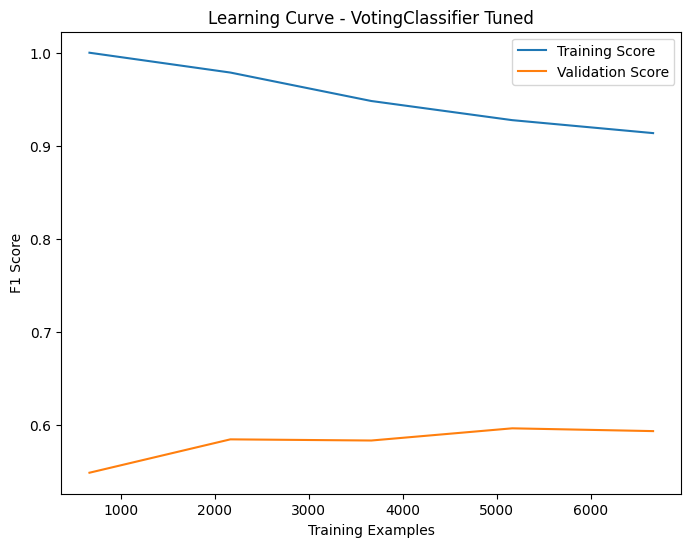

In [97]:
plt.figure(figsize=(8,6))
plt.plot(
    train_sizes_voting,
    train_mean_voting,
    label="Training Score"
)
plt.plot(
    train_sizes_voting,
    val_mean_voting,
    label="Validation Score"
)
plt.title("Learning Curve - VotingClassifier Tuned")
plt.xlabel("Training Examples")
plt.ylabel("F1 Score")
plt.legend()
plt.show()

COMPARACIÓN FINAL

In [98]:
comparacion_final_df = pd.DataFrame({

    "Modelo": [

        "Logistic Regression A",

        "Random Forest A",

        "Logistic Regression B",

        "Random Forest B",

        "XGBoost B",

        "XGBoost Tuneado",

        "VotingClassifier",

        "VotingClassifier Tuneado"
    ],

    "Accuracy": [

        0.79,

        0.87,

        0.71,

        0.86,

        0.85,

        0.86,

        0.86,

        0.86
    ],

    "Precision": [

        0.41,

        0.81,

        0.39,

        0.79,

        0.68,

        0.74,

        0.70,

        0.71
    ],

    "Recall": [

        0.03,

        0.47,

        0.72,

        0.44,

        0.51,

        0.51,

        0.54,

        0.56
    ],

    "F1-Score": [

        0.06,

        0.60,

        0.51,

        0.56,

        0.58,

        0.60,

        0.61,

        0.62
    ],

    "ROC-AUC": [

        0.67,

        0.86,

        0.78,

        0.86,

        0.85,

        0.85,

        0.86,

        0.86
    ]
})

comparacion_final_df

,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression A,0.79,0.41,0.03,0.06,0.67
1,Random Forest A,0.87,0.81,0.47,0.60,0.86
2,Logistic Regression B,0.71,0.39,0.72,0.51,0.78
3,Random Forest B,0.86,0.79,0.44,0.56,0.86
4,XGBoost B,0.85,0.68,0.51,0.58,0.85
5,XGBoost Tuneado,0.86,0.74,0.51,0.60,0.85
6,VotingClassifier,0.86,0.70,0.54,0.61,0.86
7,VotingClassifier Tuneado,0.86,0.71,0.56,0.62,0.86


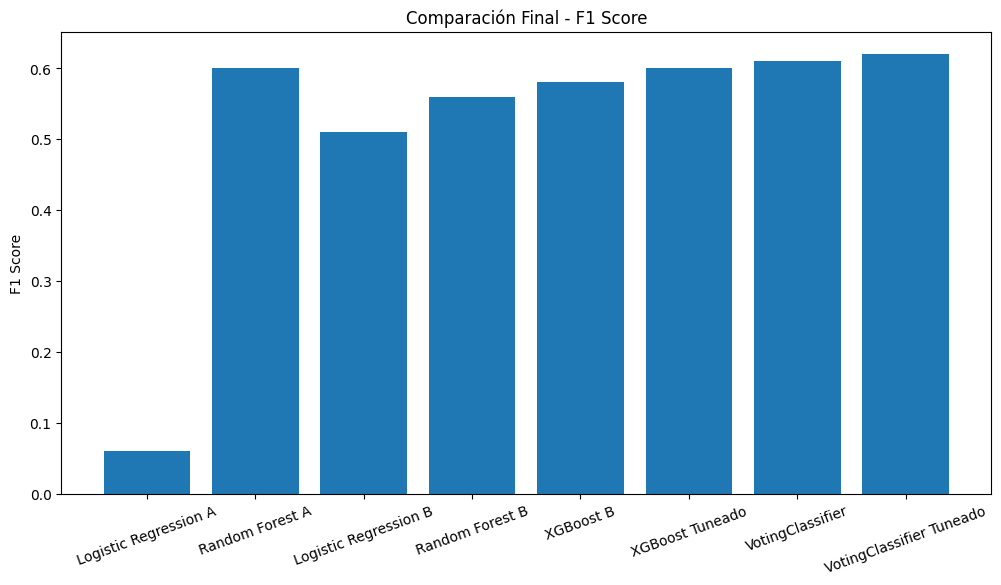

In [99]:
plt.figure(figsize=(12,6))

plt.bar(
    comparacion_final_df["Modelo"],
    comparacion_final_df["F1-Score"]
)

plt.xticks(rotation=20)

plt.title("Comparación Final - F1 Score")

plt.ylabel("F1 Score")

plt.show()

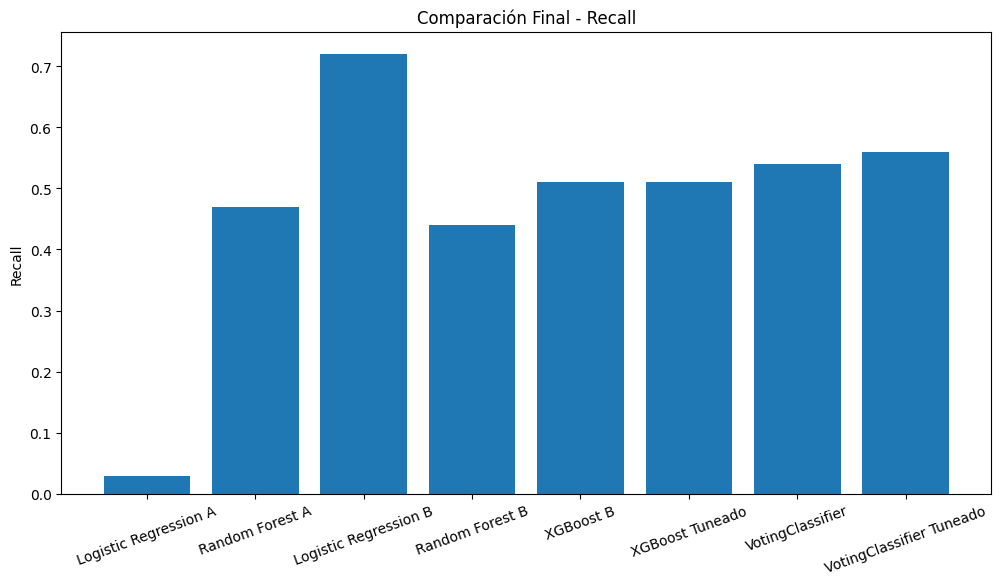

In [100]:
plt.figure(figsize=(12,6))

plt.bar(
    comparacion_final_df["Modelo"],
    comparacion_final_df["Recall"]
)

plt.xticks(rotation=20)

plt.title("Comparación Final - Recall")

plt.ylabel("Recall")

plt.show()

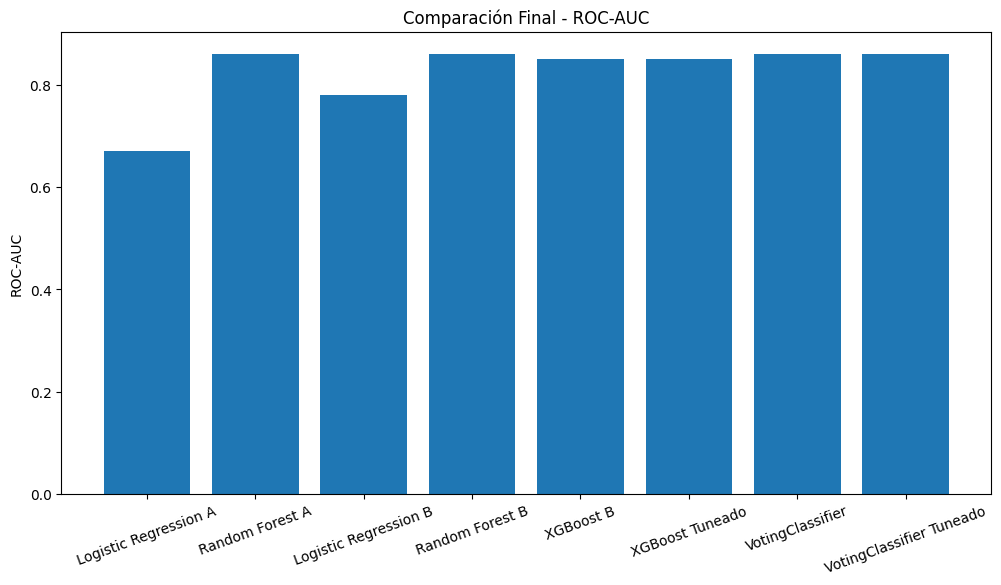

In [101]:
plt.figure(figsize=(12,6))

plt.bar(
    comparacion_final_df["Modelo"],
    comparacion_final_df["ROC-AUC"]
)

plt.xticks(rotation=20)

plt.title("Comparación Final - ROC-AUC")

plt.ylabel("ROC-AUC")

plt.show()